In [2]:
from langchain.chat_models import init_chat_model
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [4]:

class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

In [8]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return {
        "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL": 87.6
    }.get(symbol, 0.0)

tools = [get_stock_price]

llm = init_chat_model("google_genai:gemini-3.8-flash")
llm_with_tools = llm.bind_tools(tools)

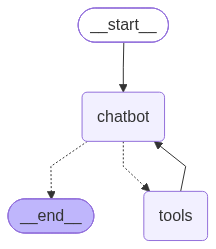

In [9]:
def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node(chatbot)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")
graph = builder.compile()

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:

state = graph.invoke({"messages": [{"role": "user", "content": "What is the price of AAPL stock right now?"}]})
print(state["messages"][-1].content)

[{'type': 'text', 'text': 'The current price of AAPL stock is $100.40.', 'extras': {'signature': 'ErABCq0BAWkUfRMkXXNXUmgIyPW5CORCEYEoZr8kZjhSHRz5WEIeIzqoqKm+neUrn9T6zynYSgTSyNC9pYrjoJXqmPLPEdDvCsoovp3/Q/QuxyLPE0uTzRVF2tlLo6Dhs5MC2LUlEk2n8j8nk0sExhx13+X2jLeQ/NG6uNN2gDOqe+9IecmEIba70mKr+0zedexktOz7AY+XUFnHWGbnC5V3r30z8WwAqRT/EGbXelAKwY4='}}]


In [11]:

state = graph.invoke({"messages": [{"role": "user", "content": "Who invented theory of relativity? print person name only"}]})
print(state["messages"][-1].content)

[{'type': 'text', 'text': 'Albert Einstein', 'extras': {'signature': 'ErYCCrMCAWkUfRN5i3MslWm0ttEajjE0nW0SR28pkt2A1+T5GTUbIdM5TNwoXOtYc2yeCUiNdTfNO1okt9gt19ZmtJnVmnETQpGq9XQIEOuJtwb1KrD7fDMmMG30yDrY+t3Fty7a3/pN1JQoQWzv16/VK05dL3GDCuOQX8180nNquAu5fd1vdBF7sLznmwk2q7BxLO7dWMSGniR4ZOy4L2tXY0b8Hbd83krnAK8TVizjuiRbHCAQ/cuBNL9I4lrYk7dla8DE93XT9Az3WMPl5MqCEcSyxZgfxj1BlFdbUCD76hqxscN+HwYecGvVB9pVaAGgQjjD4PP2KnPX0JidvPVA1mEvRdJyR42SZVM17cvNX+wUMhLyd6C6/rUWs2h383TYWAspyAR9+A38kgUtNGUAw4zIJ50OqA=='}}]


In [12]:
msg = "I want to buy 20 AMZN stocks using current price. Then 15 MSFT. What will be the total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]})
print(state["messages"][-1].content)

GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.8-flash\nPlease retry in 47.903744888s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier',